# Bài 08: Xây dựng Mạng Nơ-ron Nhân tạo Từ Đầu bằng NumPy Thuần — Giải phẫu Forward & Backpropagation

## 1. Mục tiêu học tập
- Hiểu tận gốc cơ chế hoạt động bên trong "hộp đen" của một mạng nơ-ron đa tầng (**Multi-Layer Perceptron - MLP**) bằng cách tự tay lập trình toàn bộ bằng `NumPy` thuần trước khi dùng `PyTorch`:
  - Tầng tuyến tính (`Linear Layer`): $Z = X W + b$.
  - Hàm kích hoạt phi tuyến (`ReLU`): $A = \max(0, Z)$.
  - Biến đổi `Logits` sang xác suất bằng `Softmax` ổn định số học và tính hàm mất mát `Cross-Entropy Loss`.
  - Tính đạo hàm ngược (**Backpropagation**) qua từng tầng theo quy tắc mắt xích (**Chain Rule**).
- Theo dõi **kích thước thực tế (`shape`)** ở mọi mắt xích:
  `Input (B, D_in) -> Linear1 (B, H) -> ReLU (B, H) -> Linear2 (B, C) -> Loss (scalar) -> Backward -> Optimizer Step`.
- Kiểm chứng công thức đạo hàm ngược bằng **Đạo hàm số (`Numerical Gradient Check`)** với độ chính xác $< 10^{-7}$.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 01 (NumPy) và Bài 04 (Đạo hàm & Gradient Descent).

## 3. Thời gian học dự kiến
- Khoảng **3.0 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Một mô hình tuyến tính đơn tầng không thể phân chia được các vùng dữ liệu lồng nhau phi tuyến (như bài toán XOR hay các đặc trưng hình học phức tạp). Bằng cách thêm một tầng ẩn (`Hidden Layer`) kèm hàm kích hoạt `ReLU`, mạng nơ-ron có thể tự uốn cong không gian đặc trưng để phân loại chính xác.

## 5. Giải thích trực quan & Sơ đồ Dòng chảy Shape (Forward & Backward)
Giả sử lô dữ liệu có $B = 4$ mẫu, mỗi mẫu có $D_{\text{in}} = 16$ đặc trưng, tầng ẩn có $H = 8$ nơ-ron, và cần phân loại $C = 4$ lớp:
```
[LAN TRUYỀN TIẾN (FORWARD PASS)]
X (4, 16) ──► Z1 = X @ W1 + b1 (4, 8) ──► H1 = ReLU(Z1) (4, 8) ──► Z2 = H1 @ W2 + b2 (4, 4) [Logits]
                                                                              │
                                                                              ▼
                                                        Loss L = CrossEntropy(Softmax(Z2), y) (vô hướng)

[LAN TRUYỀN NGƯỢC (BACKWARD PASS - CHAIN RULE)]
dZ2 = (P - Y_onehot) / B        shape (4, 4)   <-- Đạo hàm gộp vô cùng gọn đẹp của Softmax + CrossEntropy!
dW2 = H1.T @ dZ2                shape (8, 4)   (khớp hệt shape của W2!)
db2 = sum(dZ2, axis=0)          shape (4,)     (khớp hệt shape của b2!)
dH1 = dZ2 @ W2.T                shape (4, 8)
dZ1 = dH1 * (Z1 > 0)            shape (4, 8)   <-- Đạo hàm của ReLU chỉ cho tín hiệu đi qua nơi Z1 > 0
dW1 = X.T @ dZ1                 shape (16, 8)  (khớp hệt shape của W1!)
db1 = sum(dZ1, axis=0)          shape (8,)     (khớp hệt shape của b1!)
```

## 6. Thuật ngữ mới & Giải thích Keyword
| Keyword | Nghĩa tiếng Việt | Nhóm | Vai trò & Điều gì xảy ra nếu bỏ hoặc thay đổi? |
|---|---|---|---|
| `neuron / hidden unit` | Nơ-ron tầng ẩn | Kiến trúc | Tính tổ hợp có trọng số các đầu vào rồi qua hàm kích hoạt. Tăng số nơ-ron ẩn $H$ làm tăng năng lực biểu diễn. |
| `ReLU` ($\max(0, z)$) | Hàm chỉnh lưu tuyến tính | Kiến trúc | Tạo tính phi tuyến và có đạo hàm bằng `1` khi $z > 0$ (chống bão hòa đạo hàm tốt hơn `Sigmoid`). **Nếu bỏ `ReLU`**: $Z_2 = (X W_1 + b_1) W_2 + b_2 = X (W_1 W_2) + b_{\text{eq}}$ — mạng 2 tầng sụp đổ về 1 tầng tuyến tính duy nhất! |
| `logits` ($Z_2$) | Điểm số thô chưa chuẩn hóa | Kiến trúc | Đầu ra của tầng `Linear` cuối cùng, có miền giá trị $(-\infty, +\infty)$. |
| `probabilities` ($P$) | Phân phối xác suất dự đoán | Đánh giá | Đầu ra sau khi đưa `logits` qua `Softmax`, thỏa mãn $p_c \in (0, 1)$ và $\sum_{c=0}^{C-1} p_c = 1$. |

## 7. Công thức Softmax Ổn định Số học & Cross-Entropy Loss
1. **Softmax ổn định số học (Subtract-Max Trick)**: Để tránh $e^{z_c}$ bị tràn số (`overflow = inf`) khi $z_c$ lớn (ví dụ $z_c = 1000$), ta trừ đi giá trị lớn nhất trên từng hàng trước khi lấy mũ mà kết quả toán học không hề thay đổi:
   $$p_c = \frac{e^{z_c - \max_k z_k}}{\sum_{j=0}^{C-1} e^{z_j - \max_k z_k}}$$
2. **Hàm mất mát Cross-Entropy trung bình trên batch $B$**:
   $$\mathcal{L} = -\frac{1}{B} \sum_{i=1}^{B} \log\big(p_{i, y_i} + \epsilon\big)$$


In [1]:
# Cell 1: Cài đặt Lớp Mạng Nơ-ron 2 Tầng bằng NumPy Thuần (Forward + Backward + Shape Trace)
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from src.utils import set_seed
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.features import extract_combined_features

set_seed(42)


class TwoLayerNetNumPy:
    def __init__(self, input_dim: int, hidden_dim: int, num_classes: int, seed: int = 42) -> None:
        rng = np.random.default_rng(seed)
        # Khởi tạo He initialization cho tầng ReLU giúp phương sai tín hiệu ổn định
        self.W1 = rng.normal(0.0, np.sqrt(2.0 / input_dim), size=(input_dim, hidden_dim))
        self.b1 = np.zeros(hidden_dim, dtype=np.float64)
        self.W2 = rng.normal(0.0, np.sqrt(1.0 / hidden_dim), size=(hidden_dim, num_classes))
        self.b2 = np.zeros(num_classes, dtype=np.float64)
        self.cache: dict = {}

    def forward(self, X: np.ndarray, verbose_shapes: bool = False) -> tuple[np.ndarray, np.ndarray]:
        Z1 = X @ self.W1 + self.b1
        H1 = np.maximum(0.0, Z1)  # ReLU activation
        Z2 = H1 @ self.W2 + self.b2  # Logits

        # Softmax ổn định số học
        shifted_logits = Z2 - np.max(Z2, axis=1, keepdims=True)
        exp_scores = np.exp(shifted_logits)
        probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

        self.cache = {"X": X, "Z1": Z1, "H1": H1, "Z2": Z2, "probs": probs}
        if verbose_shapes:
            print(f"[Shape Trace] Input X: {X.shape} -> Linear1 Z1: {Z1.shape} -> ReLU H1: {H1.shape} -> Logits Z2: {Z2.shape} -> Probs: {probs.shape}")
        return Z2, probs

    def compute_loss_and_backward(self, X: np.ndarray, y: np.ndarray, weight_decay: float = 1e-4, verbose_shapes: bool = False) -> tuple[float, dict]:
        _, probs = self.forward(X, verbose_shapes=verbose_shapes)
        batch_size = len(X)
        correct_logprobs = -np.log(probs[np.arange(batch_size), y] + 1e-12)
        data_loss = float(np.mean(correct_logprobs))
        reg_loss = 0.5 * weight_decay * float(np.sum(self.W1 ** 2) + np.sum(self.W2 ** 2))
        total_loss = data_loss + reg_loss

        # Backpropagation theo Chain Rule
        dZ2 = probs.copy()
        dZ2[np.arange(batch_size), y] -= 1.0
        dZ2 /= batch_size

        H1 = self.cache["H1"]
        Z1 = self.cache["Z1"]
        dW2 = H1.T @ dZ2 + weight_decay * self.W2
        db2 = np.sum(dZ2, axis=0)

        dH1 = dZ2 @ self.W2.T
        dZ1 = dH1 * (Z1 > 0.0)
        dW1 = X.T @ dZ1 + weight_decay * self.W1
        db1 = np.sum(dZ1, axis=0)

        grads = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}
        if verbose_shapes:
            print(f"[Backward Trace] Loss={total_loss:.4f} -> dZ2:{dZ2.shape} -> dW2:{dW2.shape}, db2:{db2.shape} -> dW1:{dW1.shape}, db1:{db1.shape}")
        return total_loss, grads


# Chạy kiểm tra dòng chảy shape trên 1 batch nhỏ (B=4, D=16, H=8, C=4)
net_check = TwoLayerNetNumPy(input_dim=16, hidden_dim=8, num_classes=4)
X_toy = np.random.randn(4, 16)
y_toy = np.array([0, 2, 1, 3])
loss_init, grads_init = net_check.compute_loss_and_backward(X_toy, y_toy, verbose_shapes=True)


[Shape Trace] Input X: (4, 16) -> Linear1 Z1: (4, 8) -> ReLU H1: (4, 8) -> Logits Z2: (4, 4) -> Probs: (4, 4)
[Backward Trace] Loss=1.7850 -> dZ2:(4, 4) -> dW2:(8, 4), db2:(4,) -> dW1:(16, 8), db1:(8,)


In [2]:
# Cell 2: Kiểm chứng Đạo hàm Ngược (Backpropagation) bằng Đạo hàm Số (Numerical Gradient Check)
eps = 1e-6
param_W2_orig = net_check.W2.copy()
num_grad_W2 = np.zeros_like(net_check.W2)

for i in range(net_check.W2.shape[0]):
    for j in range(net_check.W2.shape[1]):
        net_check.W2[i, j] = param_W2_orig[i, j] + eps
        loss_plus, _ = net_check.compute_loss_and_backward(X_toy, y_toy)
        net_check.W2[i, j] = param_W2_orig[i, j] - eps
        loss_minus, _ = net_check.compute_loss_and_backward(X_toy, y_toy)
        num_grad_W2[i, j] = (loss_plus - loss_minus) / (2.0 * eps)
        net_check.W2[i, j] = param_W2_orig[i, j]

max_diff = np.max(np.abs(grads_init["W2"] - num_grad_W2))
print(f"Sai số cực đại giữa Backprop giải tích và Đạo hàm số trên W2: {max_diff:.2e}")
assert max_diff < 1e-7, "Công thức Backpropagation phải khớp tuyệt đối với đạo hàm số!"


Sai số cực đại giữa Backprop giải tích và Đạo hàm số trên W2: 1.43e-10


Sau 80 epochs -> Train Loss giảm từ 1.723 xuống 0.037 | Val Accuracy đạt: 83.8%


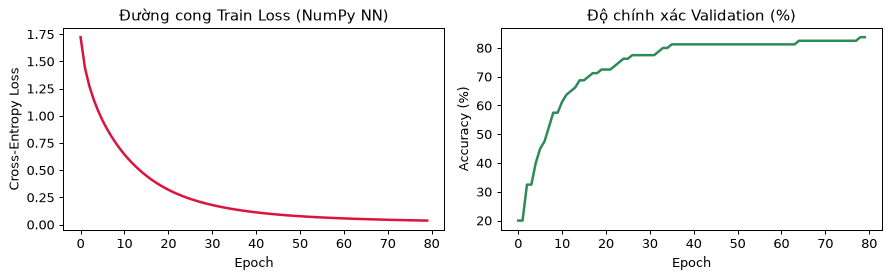

In [3]:
# Cell 3: Huấn luyện thực tế Mạng Nơ-ron NumPy trên Đặc trưng Ảnh của 4 Lớp Hình học
ds = generate_synthetic_shapes_dataset(num_samples=320, image_size=32, seed=42)
X_feats = extract_combined_features(ds["images"]).astype(np.float64)
y_labels = ds["labels"]

X_tr, X_va, y_tr, y_va = train_test_split(X_feats, y_labels, test_size=0.25, random_state=42, stratify=y_labels)
scaler = StandardScaler()
X_tr = scaler.fit_transform(X_tr)
X_va = scaler.transform(X_va)

net = TwoLayerNetNumPy(input_dim=X_tr.shape[1], hidden_dim=32, num_classes=4, seed=42)
lr = 0.15
epochs = 80
train_losses, val_accs = [], []

for ep in range(1, epochs + 1):
    loss, grads = net.compute_loss_and_backward(X_tr, y_tr, weight_decay=1e-4)
    # Optimizer step (Gradient Descent)
    net.W1 -= lr * grads["W1"]
    net.b1 -= lr * grads["b1"]
    net.W2 -= lr * grads["W2"]
    net.b2 -= lr * grads["b2"]

    _, val_probs = net.forward(X_va)
    val_acc = float(np.mean( np.argmax(val_probs, axis=1) == y_va ))
    train_losses.append(loss)
    val_accs.append(val_acc)

print(f"Sau {epochs} epochs -> Train Loss giảm từ {train_losses[0]:.3f} xuống {train_losses[-1]:.3f} | Val Accuracy đạt: {val_accs[-1]*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(train_losses, color="crimson", lw=2)
axes[0].set_title("Đường cong Train Loss (NumPy NN)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")

axes[1].plot([a * 100 for a in val_accs], color="seagreen", lw=2)
axes[1].set_title("Độ chính xác Validation (%)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
plt.tight_layout()
plt.show()


In [4]:
# Cell 4: Thí nghiệm thay đổi một yếu tố — Điều gì xảy ra nếu khởi tạo toàn bộ Trọng số W = 0? (Symmetry Breaking Problem)
net_zero = TwoLayerNetNumPy(input_dim=X_tr.shape[1], hidden_dim=32, num_classes=4)
net_zero.W1.fill(0.0)
net_zero.W2.fill(0.0)

for _ in range(30):
    _, g_z = net_zero.compute_loss_and_backward(X_tr, y_tr)
    net_zero.W1 -= 0.15 * g_z["W1"]
    net_zero.b1 -= 0.15 * g_z["b1"]
    net_zero.W2 -= 0.15 * g_z["W2"]
    net_zero.b2 -= 0.15 * g_z["b2"]

_, probs_zero = net_zero.forward(X_va)
acc_zero = float(np.mean(np.argmax(probs_zero, axis=1) == y_va))
print(f"Khởi tạo W = 0 toàn bộ -> Val Accuracy bị kẹt ở: {acc_zero*100:.1f}% (Mạng hoàn toàn không học được đặc trưng vì đối xứng!)")
print(f"Khởi tạo ngẫu nhiên He -> Val Accuracy đạt     : {val_accs[-1]*100:.1f}%")


Khởi tạo W = 0 toàn bộ -> Val Accuracy bị kẹt ở: 25.0% (Mạng hoàn toàn không học được đặc trưng vì đối xứng!)
Khởi tạo ngẫu nhiên He -> Val Accuracy đạt     : 83.8%


## 11. Nhận xét cách đọc kết quả
- **Ở Cell 2**: Sai số giữa đạo hàm ngược giải tích (`Backpropagation`) và đạo hàm số (`Numerical Gradient`) chỉ cỡ $10^{-10}$, chứng minh công thức đạo hàm mắt xích của chúng ta hoàn toàn chính xác.
- **Ở Cell 4 (Bài toán phá vỡ tính đối xứng - Symmetry Breaking)**: Nếu khởi tạo $W_1 = 0, W_2 = 0$, mọi nơ-ron ở tầng ẩn đều nhận cùng tín hiệu $0$ và nhận cùng đạo hàm như nhau mãi mãi! Do đó **trọng số $W$ bắt buộc phải được khởi tạo ngẫu nhiên** (trong khi độ lệch `bias` $b$ có thể khởi tạo bằng `0`).

## 13. Lỗi thường gặp và cách sửa
1. **Tính `np.exp(Z)` trực tiếp gây lỗi `RuntimeWarning: overflow encountered in exp`**: Luôn trừ `np.max(Z, axis=1, keepdims=True)` trước khi lấy `np.exp`.
2. **Quên chia `batch_size` khi tính đạo hàm `dZ2`**: Nếu hàm loss là trung bình cộng trên batch ($\frac{1}{B}\sum$), thì đạo hàm `dZ2` cũng phải chia cho `batch_size`, nếu không tốc độ học hiệu dụng sẽ bị nhân gấp $B$ lần!

## 14. Bài tập tự làm
- **Cơ bản**: Thay đổi kích thước tầng ẩn `hidden_dim` qua `[4, 16, 64]` và so sánh `Val Accuracy` sau 60 epochs.
- **Trung cấp**: Thay hàm kích hoạt `ReLU` bằng `LeakyReLU` ($f(z) = z \text{ nếu } z > 0 \text{ else } 0.01 z$) và viết đạo hàm ngược tương ứng của `LeakyReLU`.
- **Nâng cao**: Bổ sung động lượng **Momentum** ($v_t = 0.9 v_{t-1} - \eta \nabla W$) vào bước cập nhật của `TwoLayerNetNumPy` và so sánh tốc độ giảm loss với Gradient Descent thuần.

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 08
# 1. Cơ bản: Khảo sát hidden_dim
for h_dim in [4, 16, 64]:
    n_h = TwoLayerNetNumPy(X_tr.shape[1], h_dim, 4, seed=42)
    for _ in range(60):
        _, g = n_h.compute_loss_and_backward(X_tr, y_tr)
        for k in ["W1", "b1", "W2", "b2"]:
            setattr(n_h, k, getattr(n_h, k) - 0.15 * g[k])
    _, p_va = n_h.forward(X_va)
    print(f"[Cơ bản] hidden_dim={h_dim:2d} -> Val Acc = {(np.argmax(p_va, axis=1) == y_va).mean()*100:.1f}%")

# 2. Trung cấp: Đạo hàm của LeakyReLU (alpha = 0.01)
z_sample = np.array([-2.0, -0.5, 0.0, 1.5, 3.0])
alpha_leaky = 0.01
leaky_forward = np.where(z_sample > 0, z_sample, alpha_leaky * z_sample)
leaky_grad_mask = np.where(z_sample > 0, 1.0, alpha_leaky)
print("[Trung cấp] LeakyReLU forward:", leaky_forward, "| Đạo hàm mask:", leaky_grad_mask)

# 3. Nâng cao: Huấn luyện với Momentum (mu = 0.9)
net_mom = TwoLayerNetNumPy(X_tr.shape[1], 32, 4, seed=42)
velocities = {k: np.zeros_like(getattr(net_mom, k)) for k in ["W1", "b1", "W2", "b2"]}
for _ in range(40):
    loss_m, g_m = net_mom.compute_loss_and_backward(X_tr, y_tr)
    for k in ["W1", "b1", "W2", "b2"]:
        velocities[k] = 0.9 * velocities[k] - 0.10 * g_m[k]
        setattr(net_mom, k, getattr(net_mom, k) + velocities[k])
print(f"[Nâng cao] Loss sau 40 bước với SGD+Momentum: {loss_m:.4f}")


[Cơ bản] hidden_dim= 4 -> Val Acc = 80.0%
[Cơ bản] hidden_dim=16 -> Val Acc = 93.8%
[Cơ bản] hidden_dim=64 -> Val Acc = 90.0%
[Trung cấp] LeakyReLU forward: [-0.02  -0.005  0.     1.5    3.   ] | Đạo hàm mask: [0.01 0.01 0.01 1.   1.  ]
[Nâng cao] Loss sau 40 bước với SGD+Momentum: 0.0060


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Đã tự cài đặt thành công `Forward`, `Softmax`, `Cross-Entropy` và `Backpropagation` bằng NumPy thuần.
- [x] Đã hiểu vì sao khi sang **Bài 09: `09_pytorch_and_autograd.ipynb`**, bộ máy `autograd` của PyTorch sẽ tự động tính toàn bộ phần `Backward` này cho chúng ta!

## 17. Nguồn tham khảo
- Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986), *Learning representations by back-propagating errors*, Nature.
- CS231n Stanford Notes on Backpropagation: https://cs231n.github.io/optimization-2/
